In [1]:
# Imports
import os

import pandas as pd 

# Turn off annoying warnings
import warnings
warnings.filterwarnings('ignore')

# Make sure the environment is good
import numpy as np

import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import xarray as xr
import os

from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times,ll_to_xy,xy_to_ll)
import matplotlib.patches as mpatches

In [2]:
def gust_calc(WRF_DIRECTORY, WRF_FILES):

    _WRF_FILES = [os.path.abspath(os.path.expanduser(os.path.join(WRF_DIRECTORY, f))) for f in WRF_FILES]
    #print(_WRF_FILES)
    # Check that the WRF files exist
    for f in _WRF_FILES:
        if not os.path.exists(f):
            raise ValueError("{} does not exist. "
                "Check for typos or incorrect directory.")
    
    #file_paths = multiple_wrf_files() # Necessary due to single_wrf_file being a function
    #print(file_path)

    #print(_WRF_FILES)
    wrf_files = [Dataset(f) for f in _WRF_FILES]
    
    #wrf_join = getvar(wrf_files, "WSPD10MAX", timeidx=ALL_TIMES, method="join")
    wrf_join = getvar(wrf_files, "UP_HELI_MAX", timeidx=ALL_TIMES, method="join")
    #for i in range(0,61):
        
        #print(np.max(to_np(wrf_join[i,:,:])))
    wrf_max=wrf_join.max('file')

    return(wrf_max)

In [3]:
uh_nourban=np.zeros([11,250,250])

for i in range(0,11):
    print(i)
    WRF_DIRECTORY="/glade/campaign/ral/nsap/fdemartin/no_urban/"+str(i)+"/"
    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()
    
    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]
    
    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES
    
    uh_nourban[i,:,:]=gust_calc(WRF_DIRECTORY,WRF_FILES)

uh_nourban_mean=np.mean(uh_nourban,axis=0)

0
1
2
3
4
5
6
7
8
9
10


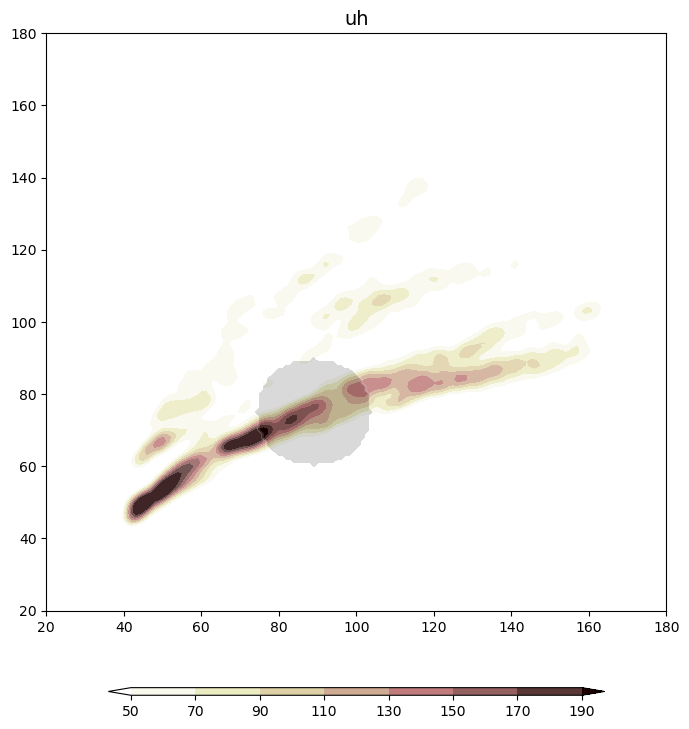

In [7]:
smooth_uh = smooth2d(uh_nourban_mean, 10, cenweight=8)
x=np.arange(0,250,1)
y=np.arange(0,250,1)

ncfile = Dataset(WRF_DIRECTORY+"/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(50,200,20)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)

ax.set_title('uh',fontsize=14)
ax.set_ylim(20,180)
ax.set_xlim(20,180)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, smooth_uh, levels=levels, cmap='pink_r', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)

# for i in range(0,11):
#     ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/uh_green'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [4]:
uh=np.zeros([11,250,250])

for i in range(0,11):
    print(i)
    WRF_DIRECTORY="/glade//campaign/ral/nsap/fdemartin/30km_bubble_north/"+str(i)+"/"
    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()
    
    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]
    
    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES
    
    uh[i,:,:]=gust_calc(WRF_DIRECTORY,WRF_FILES)
    print(np.max(uh[i,:,:]))
uh_mean=np.mean(uh,axis=0)

0
767.1282348632812
1
556.4109497070312
2
554.2418212890625
3
745.5426635742188
4
577.3367919921875
5
658.37353515625
6
587.1985473632812
7
652.1826171875
8
540.906982421875
9
555.0777587890625
10
657.370849609375


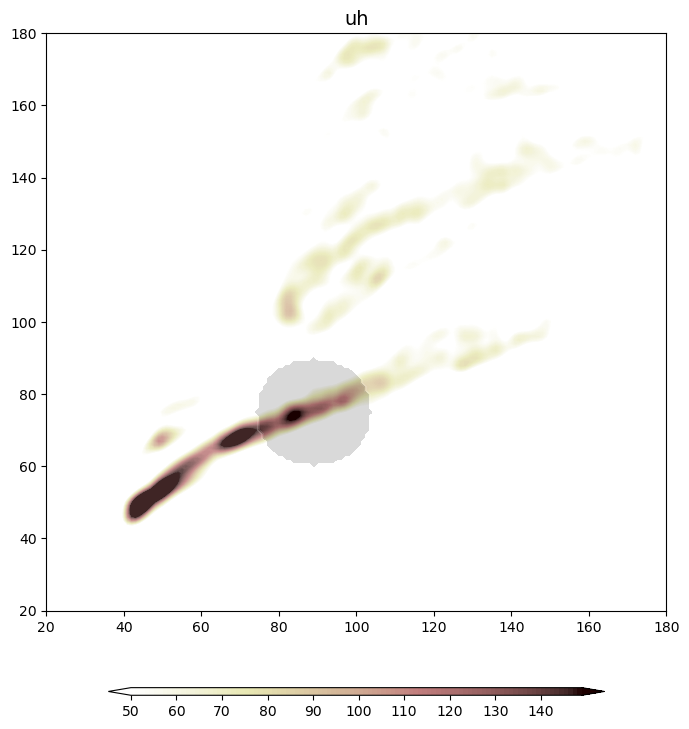

In [4]:
x=np.arange(0,250,1)
y=np.arange(0,250,1)
smooth_uh = smooth2d(uh_mean, 10, cenweight=8)

ncfile = Dataset(WRF_DIRECTORY+"/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(50,150,1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('uh',fontsize=14)
ax.set_ylim(20,180)
ax.set_xlim(20,180)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
#for i in range(0,11):
#cf = ax.contourf(x, y, uh[3,:,:])
#cf = ax.contourf(x, y, uh[9,:,:], levels=[150,5000,6000],colors=['red','black'])
# cf = ax.contour(x, y, uh[0,:,:], levels=[150,5000,6000],colors=['y','black'])
# cf = ax.contour(x, y, uh[2,:,:], levels=[150,5000,6000],colors=['b','black'])
# cf = ax.contour(x, y, uh[3,:,:], levels=[150,5000,6000],colors=['g','black'])
# cf = ax.contour(x, y, uh[4,:,:], levels=[150,5000,6000],colors=['m','black'])
# cf = ax.contour(x, y, uh[5,:,:], levels=[150,5000,6000],colors=['gray','black'])
# cf = ax.contour(x, y, uh[6,:,:], levels=[150,5000,6000],colors=['c','black'])
cf = ax.contourf(x, y, smooth_uh, levels=levels, cmap='pink_r', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)

# for i in range(0,11):
#     ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/uh_PV'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [3]:
uh=np.zeros([11,250,250])

for i in range(0,11):
    print(i)
    WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/OKC/"+str(i)+"/"
    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()
    
    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]
    
    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES
    
    uh[i,:,:]=gust_calc(WRF_DIRECTORY,WRF_FILES)

uh_OKC=np.mean(uh,axis=0)

0
1
2
3
4
5
6
7
8
9
10


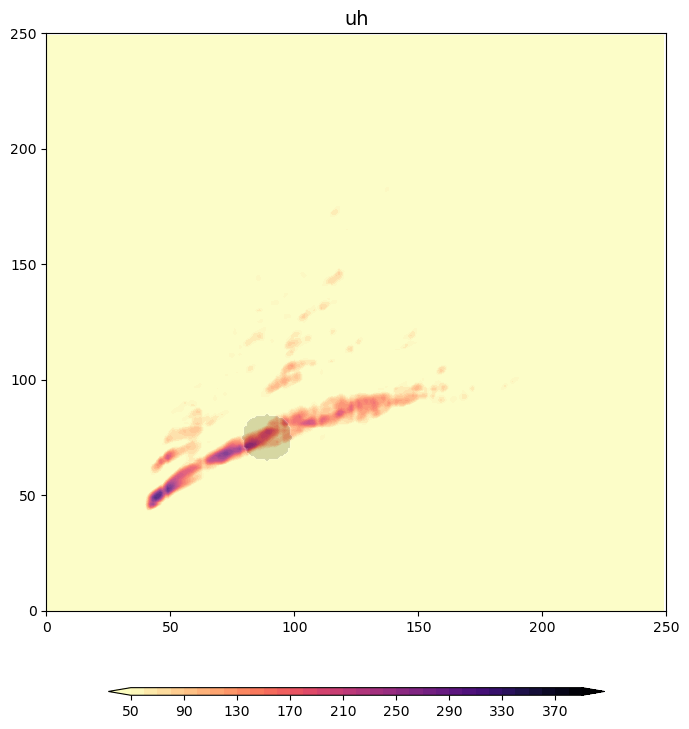

In [4]:
x=np.arange(0,250,1)
y=np.arange(0,250,1)

ncfile = Dataset(WRF_DIRECTORY+"/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(50,400,10)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('uh',fontsize=14)
ax.set_ylim(0,250)
ax.set_xlim(0,250)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, uh_OKC, levels=levels, cmap='magma_r', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)

# for i in range(0,11):
#     ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/uh'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [5]:
uh_bn=np.zeros([11,250,250])

for i in range(0,11):
    print(i)
    WRF_DIRECTORY="/glade//campaign/ral/nsap/fdemartin/30km/"+str(i)+"/"
    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()
    
    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]
    
    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES
    
    uh_bn[i,:,:]=gust_calc(WRF_DIRECTORY,WRF_FILES)

uh_bn_mean=np.mean(uh_bn,axis=0)

0
1
2
3
4
5
6
7
8
9
10


In [5]:
uh_Milan=np.zeros([11,250,250])

for i in range(0,11):
    print(i)
    WRF_DIRECTORY="/glade//campaign/ral/nsap/fdemartin/no_urban/"+str(i)+"/"
    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()
    
    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]
    
    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES
    
    uh_Milan[i,:,:]=gust_calc(WRF_DIRECTORY,WRF_FILES)

uh_nourban_mean=np.mean(uh_Milan,axis=0)

0
1
2
3
4
5
6
7
8
9
10


In [6]:
file_path="/glade/derecho/scratch/fdemartin/ens/no_urban/"

cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape[i,:,:] = to_np(getvar(ncfile, 'cape2d',timeidx=0))[0,:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/campaign/ral/nsap/fdemartin/30km_bubble_north/"

cape2=np.zeros([11,250,250])
w950=np.zeros([11,250,250])
p2=np.zeros([11,63,250,250])
wa2=np.zeros([11,63,250,250])

ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape2[i,:,:] = to_np(getvar(ncfile, 'cape2d',timeidx=0))[0,:,:]
    wa2[i,:,:,:] = to_np(getvar(ncfile, 'wa',timeidx=0))[:,:,:]
    p2[i,:,:,:] = to_np(getvar(ncfile, 'pressure',timeidx=0))
    w950[i,:,:] = interplevel(wa2[i,:,:,:], p2[i,:,:,:], 950)

w950_diff=np.mean(w950,axis=0)
cape2=np.mean(cape2,axis=0)

diff=cape2-cape

In [8]:
file_path="/glade/derecho/scratch/fdemartin/ens/30km/"

ua2=np.zeros([11,250,250])
va2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    ua2[i,:,:],va2[i,:,:] = to_np(getvar(ncfile, 'uvmet10',timeidx=0))#[:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

ua2=np.mean(ua2,axis=0)
va2=np.mean(va2,axis=0)

In [9]:

file_path="/glade/campaign/ral/nsap/fdemartin/30km/"

srh=np.zeros([11,250,250])
for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    srh[i,:,:] = to_np(getvar(ncfile, 'helicity',timeidx=0))[:,:]

srh=np.mean(srh,axis=0)

file_path="/glade/campaign/ral/nsap/fdemartin/no_urban/"

srh2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    srh2[i,:,:] = to_np(getvar(ncfile, 'helicity',timeidx=0))[:,:]

srh2=np.mean(srh2,axis=0)

srh_diff=srh-srh2

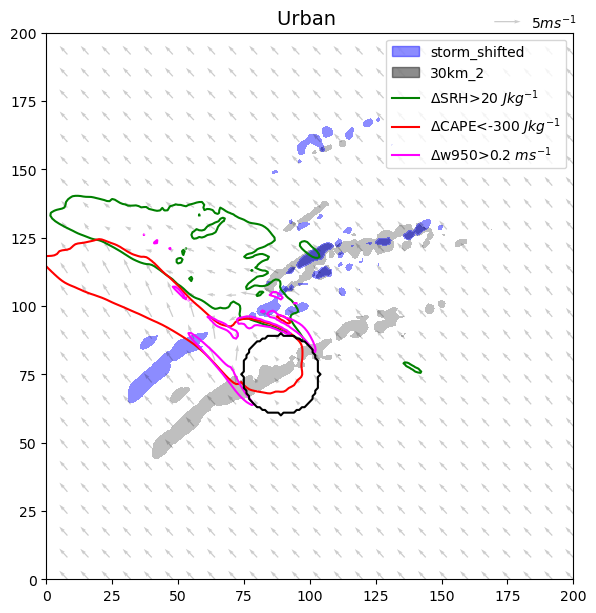

In [11]:
from matplotlib.lines import Line2D
x=np.arange(0,250,1)
y=np.arange(0,250,1)

WRF_DIRECTORY="/glade/campaign/ral/nsap/fdemartin/30km_bubble_north/"+str(i)+"/"
ncfile = Dataset(WRF_DIRECTORY+"/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(50,400,10)
fig = plt.figure(figsize=(6.8, 7.1))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('Urban ',fontsize=14)
ax.set_ylim(0,200)
ax.set_xlim(0,200)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')

#ax.contourf(x, y, uh_nourban_mean, levels=[0,80,600], colors=['white','black'], extend='both', alpha=0.45)
ax.contourf(x, y, uh_bn_mean, levels=[0,80,600], colors=['white','black'], extend='both', alpha=0.45)
ax.contourf(x, y, uh_mean, levels=[0,80,600], colors=['white','blue'], extend='both', alpha=0.45)

# Crea una patch da usare in legenda
legend_patch1 = mpatches.Patch(color='blue', alpha=0.45, label='storm_shifted')
legend_patch2 = mpatches.Patch(color='black', alpha=0.45, label='30km_2')
#legend_patch3 = mpatches.Patch(color='black', alpha=0.45, label='no_urban')

#ax.legend()

ax.contour(x, y, srh_diff, levels=[20,200], colors=['green'], linestyles=['solid'], extend='both',label='delta SRH>50$Jkg^{-1}$')
ax.contour(x, y, diff, levels=[-300,600], colors=['red'], linestyles=['solid'], extend='both',label='delta CAPE<-50$Jkg^{-1}$')
ax.contour(x, y, w950_diff, levels=[-0.2,0.5], colors=['magenta'], linestyles=['solid'], extend='both',label='delta w950>-0.5$ms^{-1}$')
gz = ax.contour(x, y, to_np(var_lu[:,:]), levels=[50,60],colors=['black'], extend='both')
#ax.legend()

legend_line1 = Line2D([0], [0], color='green', linestyle='solid', label=r'$\Delta$SRH>20 $Jkg^{-1}$')
legend_line2 = Line2D([0], [0], color='red', linestyle='solid', label=r'$\Delta$CAPE<-300 $Jkg^{-1}$')
legend_line3 = Line2D([0], [0], color='magenta', linestyle='solid', label=r'$\Delta$w950>0.2 $ms^{-1}$')

ax.legend(handles=[legend_patch1, legend_patch2,
                    legend_line1, legend_line2, legend_line3])
n=8
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.2)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
#cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)

# for i in range(0,11):
#     ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/uh_all'
fig.savefig(figname+'.png',bbox_inches='tight',dpi=300)
#plt.close()

In [10]:
file_path="/glade/derecho/scratch/fdemartin/ens/no_urban/"

cape=np.zeros([10,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,10):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape[i,:,:] = to_np(getvar(ncfile, 'cape2d',timeidx=0))[0,:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/urb_frc_Milan_30km/"

cape2=np.zeros([10,250,250])

ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

for i in range(0,10):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape2[i,:,:] = to_np(getvar(ncfile, 'cape2d',timeidx=0))[0,:,:]

cape2=np.mean(cape2,axis=0)

diff=cape2-cape

FileNotFoundError: [Errno 2] No such file or directory: '/glade/derecho/scratch/fdemartin/ens/urb_frc_Milan_30km/0/wrfout_d01_2023-05-31_14:00:00'

In [ ]:
x=np.arange(0,250,1)
y=np.arange(0,250,1)

WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/urb_frc_Milan_30km/"+str(i)+"/"
ncfile = Dataset(WRF_DIRECTORY+"/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(50,400,10)
fig = plt.figure(figsize=(6.8, 7.1))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('mean max uh',fontsize=14)
ax.set_ylim(0,200)
ax.set_xlim(0,200)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')


ax.contourf(x, y, uh_Milan_mean, levels=[0,80,600], colors=['white','black'], extend='both', alpha=0.45)
ax.contourf(x, y, uh_bn_mean, levels=[0,80,600], colors=['white','red'], extend='both', alpha=0.45)
#ax.contourf(x, y, uh_nourban_mean, levels=[0,80,600], colors=['white','blue'], extend='both', alpha=0.45)
#ax.contourf(x, y, uh_nourban_mean, levels=[0,80,600], colors=['white','blue'], extend='both', alpha=0.45)

# Crea una patch da usare in legenda
legend_patch1 = mpatches.Patch(color='blue', alpha=0.45, label='30 km bubble shifted')
legend_patch2 = mpatches.Patch(color='red', alpha=0.45, label='30 km')
legend_patch3 = mpatches.Patch(color='black', alpha=0.45, label='no urban')

#ax.legend()

ax.contour(x, y, diff, levels=[-800,-500,600], colors=['white','red'], extend='both',label='delta CAPE<-50$Jkg^{-1}$')
gz = ax.contour(x, y, to_np(var_lu[:,:]), levels=[50,60],colors=['black'], extend='both')
#ax.legend()

ax.legend(handles=[legend_patch1,legend_patch2,legend_patch3])

#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)

# for i in range(0,11):
#     ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/uh_Milan'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()